In [1]:
import sys
!{sys.executable} -m pip install -q pandas matplotlib

# 03. The 14th Five Year Plan scorecard: 2021 to 2025

The 14th plan ran from 2021 to 2025. It had 20 quantitative targets: 8 binding (promises) and 12 indicative (goals). It also had a GDP direction with no number, the first time a plan skipped a growth number. This notebook scores each target as met, missed, or not yet reported, and always shows the year of the actual figure, because a 2024 figure is not a 2025 result.

One important note before the table. The Government Work Report of March 5, 2026 states that all 20 major targets were accomplished. Independent trackers disagree on two of them: carbon intensity (about 12 percent reduction against an 18 percent target) and childcare slots (4.1 against 4.5). This project shows both the official claim and the tracker figures, and takes no position on which characterization is correct. Readers can see the arithmetic for themselves.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
PROC = "../data/processed"
CHARTS = "../charts"

score = pd.read_csv(f"{PROC}/plan_14th_scorecard.csv")
print("targets:", len(score))
print("binding:", (score.type == "binding").sum())
print("indicative:", (score.type == "indicative").sum())
print(score.status.value_counts().to_dict())
print()
print(score[["indicator", "type", "target", "actual", "actual_year", "status"]].to_string(index=False))


targets: 20
binding: 8
indicative: 12
{'met': 17, 'missed': 2, 'not yet reported': 1}

                                    indicator       type                                   target                        actual actual_year           status
Energy intensity (energy use per unit of GDP)    binding                                   -13.5%                          -15%   2021-2025              met
       Carbon intensity (CO2 per unit of GDP)    binding                                     -18%                          -12%   2021-2025           missed
                        Good air quality days    binding                                    87.5%                         89.3%        2025              met
         Surface water at grade III or better    binding                                      85%                         91.4%        2025              met
                              Forest coverage    binding                                    24.1%                      over 25% 

saved 03_scorecard_counts.png


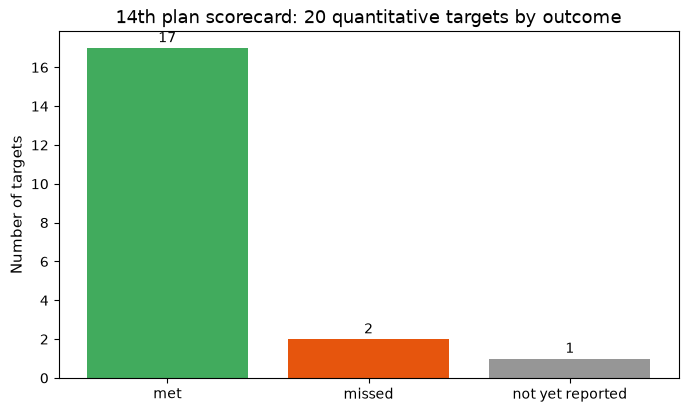

In [3]:

fig, ax = plt.subplots(figsize=(8, 4.5))
counts = score.status.value_counts()
order = ["met", "missed", "not yet reported"]
vals = [counts.get(o, 0) for o in order]
colors = ["#41ab5d", "#e6550d", "#969696"]
ax.bar(order, vals, color=colors)
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, str(v), ha="center")
ax.set_ylabel("Number of targets")
ax.set_title("14th plan scorecard: 20 quantitative targets by outcome")
plt.savefig(f"{CHARTS}/03_scorecard_counts.png", dpi=150, bbox_inches="tight")
print("saved 03_scorecard_counts.png")


## Reading the scorecard, group by group

### Environment: mostly met, one clear miss

Good air days reached 89.3 percent in 2025 against 87.5 percent targeted, a record. Surface water at grade III or better reached 91.4 percent against 85 percent. Forest coverage passed 25 percent against 24.1 percent. Energy intensity fell 15 percent over the full period on the iGDP tracker, beating the 13.5 percent target, though the official interim figure for 2021 to 2024 was minus 11.6 percent. Carbon intensity is the miss: about 12 percent against 18 percent. That miss matters because carbon is the hardest target and the one the world watches.

### Energy and food security: met, with a wording caution

Grain output topped 700 million tons for a second straight year in 2025, against a capacity target of over 650 million tons. Energy output reached 5.13 billion tons of coal equivalent against a capacity target of over 4.6 billion. Both are scored met, but output is not capacity, and the notebook keeps that distinction visible.

### People: mostly met, two to watch

Urbanization reached 67.89 percent against 65 percent. New urban jobs totaled about 62.42 million against over 55 million. Surveyed urban unemployment averaged 5.2 percent in 2025, inside the 5.5 percent ceiling. Disposable income grew 5.0 percent in real terms in 2025, matching GDP growth of 5.0 percent. Labor productivity grew 6.1 percent in 2025, faster than GDP. Life expectancy reached 79.0 years in 2024 on the official series, above the 78.3 year target, but the World Bank series puts 2024 at 78.0 years, just below target, so the two series disagree on this row. Pension coverage hit 95.0 percent exactly on the 2024 figure. Physicians reached 3.4 per 1,000 against 3.2. Childcare slots missed: 4.1 against 4.5. Working-age education has no verified 2025 actual in the sources checked, so it is scored not yet reported, not guessed.

### Innovation: met

Research spending grew about 10 percent a year on average over the plan, above the 7 percent floor, reaching about 3.93 trillion yuan in 2025, or 2.80 percent of GDP, above the OECD average of 2.72 percent for the first time. The core digital economy reached 10.5 percent of GDP in 2024, already above the 10 percent target for 2025. High-value invention patents reached 16 per 10,000 people at the end of 2025, above the target of 12.

### Growth: no number, but a result anyway

With no GDP number set, the plan cannot be scored on growth, but the result can still be stated. GDP grew 8.4, 3.0, 5.2, 5.0, and 5.0 percent from 2021 to 2025 on published annual rates. The simple mean of those five rounded rates is 5.32 percent, while the World Bank annual series averages 5.41 percent and the Government Work Report states 5.4 percent. The small gap is a rounding and vintage difference, and all three point to the same story: about 5.4 percent a year. The economy grew from about 101 trillion yuan in 2020 to 140.19 trillion yuan in 2025, an increase of about 39 trillion yuan. Per person GDP reached 99,665 yuan in 2025, or 13,953 dollars, the third straight year above 13,000 dollars.

saved 03_targets_vs_actuals.png


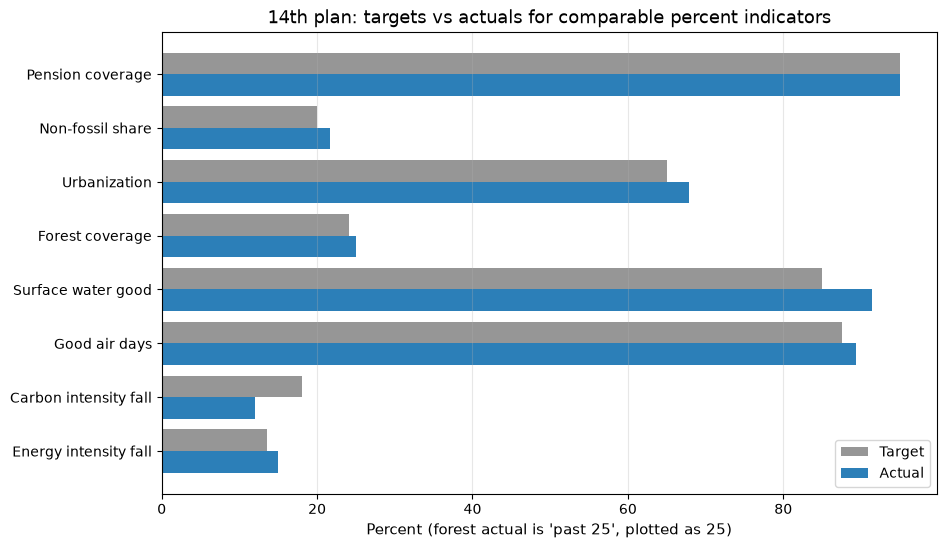

In [4]:

fig, ax = plt.subplots(figsize=(10, 6))
rows = [
    ("Energy intensity fall", 13.5, 15.0),
    ("Carbon intensity fall", 18.0, 12.0),
    ("Good air days", 87.5, 89.3),
    ("Surface water good", 85.0, 91.4),
    ("Forest coverage", 24.1, 25.0),
    ("Urbanization", 65.0, 67.89),
    ("Non-fossil share", 20.0, 21.7),
    ("Pension coverage", 95.0, 95.0),
]
labels = [r[0] for r in rows]
targets = [r[1] for r in rows]
actuals = [r[2] for r in rows]
y = range(len(rows))
ax.barh([i + 0.2 for i in y], targets, height=0.4, label="Target", color="#969696")
ax.barh([i - 0.2 for i in y], actuals, height=0.4, label="Actual", color="#2c7fb8")
ax.set_yticks(list(y))
ax.set_yticklabels(labels)
ax.set_xlabel("Percent (forest actual is 'past 25', plotted as 25)")
ax.set_title("14th plan: targets vs actuals for comparable percent indicators")
ax.legend()
ax.grid(True, axis="x", alpha=0.3)
plt.savefig(f"{CHARTS}/03_targets_vs_actuals.png", dpi=150, bbox_inches="tight")
print("saved 03_targets_vs_actuals.png")


## What the scorecard does not prove

Hitting a target does not prove the policy caused the result. Urbanization would have risen without a target. Missing a target does not prove failure of effort: carbon intensity missed partly because energy demand grew fast and coal stayed cheap and reliable. And the two disputed rows, carbon and childcare, show why attribution matters. The official report says all 20 were accomplished. The figures in this scorecard give 17 met, 2 missed, and 1 not yet reported. This project reports that count, and leaves the official claim alongside it.

Next: notebook 04 compares the provinces, where the national average hides the real story.